## ML training on sklearn dataset

In [2]:
import random
import torch
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


In [3]:
np.random.seed(1337)
random.seed(1337)

In [ ]:
# Let's make up a dataset
from sklearn.datasets import make_moons, make_blobs
X, y = make_moons(n_samples=100, noise=0.1)

# make y be -1 or 1
y = y*2 - 1

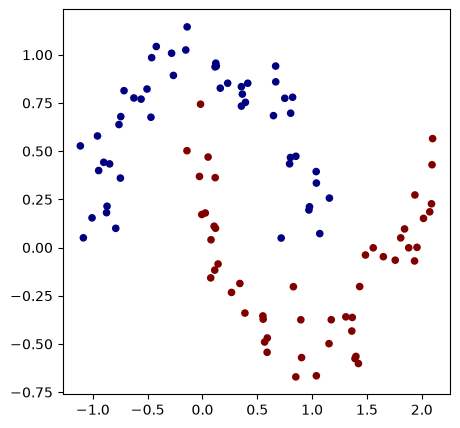

In [24]:
# Visualize in 2D
plt.figure(figsize=(5,5))
plt.scatter(X[:,0], X[:,1], c=y, s=20, cmap='jet')

In [ ]:
# Let's train an MLP to output whether it is a one or zero

array([ 1.88101391, -0.13978292, -0.87027504,  0.07525312,  1.758169  ,
        0.58961949,  1.1745536 ,  1.55717533,  0.55101677,  1.30772759,
        1.84297393, -0.84666874,  1.03844059,  2.07264872,  0.41300349,
        0.39176231,  2.09362901, -0.76122137,  0.11491   ,  0.80428525,
        0.85132372,  0.5538434 ,  0.11606056,  0.66727537,  0.35501576,
        1.154022  ,  2.09881996,  0.64763829,  0.22990014,  1.42221204,
        1.80806708,  0.10619674,  0.11189076, -0.01768776,  1.9563485 ,
        1.36173586, -0.50568735,  0.12601376, -0.26500879,  0.34110814,
        1.64964762,  0.0512925 ,  1.39098104,  2.08851394,  1.937237  ,
        0.26478663, -0.02725912,  0.82197391,  0.35510601,  0.12182599,
       -1.0071297 ,  0.66820133,  0.8025394 , -0.74485402, -0.87461128,
       -0.74856464, -0.71532277,  0.07804247,  0.75069279,  0.59115987,
        0.38725643,  0.02593991, -0.46974417, -0.28158602,  1.48636834,
       -0.95746548, -1.08618674, -0.62539273, -0.46319959,  1.15

In [23]:
y

array([ 1, -1, -1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1, -1, -1,  1,
       -1, -1, -1,  1,  1,  1, -1, -1,  1,  1, -1, -1,  1,  1,  1,  1,  1,
        1,  1, -1, -1, -1,  1,  1,  1,  1,  1,  1,  1,  1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1,  1, -1,  1,  1,  1, -1, -1,  1, -1, -1, -1,
       -1, -1, -1, -1,  1,  1,  1, -1, -1,  1, -1,  1,  1, -1,  1,  1, -1,
        1,  1, -1, -1, -1,  1, -1, -1,  1, -1, -1,  1, -1, -1, -1])

## 2.1 Lean Pytorch Implementation

In [37]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import make_moons

# 1. Data
X, y = make_moons(n_samples=100, noise=0.1, random_state=42)
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y*2 - 1, dtype=torch.float32)

# 2. Model, Optimizer (with built-in L2 weight decay), and Scheduler
model = nn.Sequential(
    nn.Linear(2, 16), nn.ReLU(),
    nn.Linear(16, 16), nn.ReLU(),
    nn.Linear(16, 1), nn.Flatten(0) # Flattens (B, 1) -> (B,)
)
optimizer = torch.optim.SGD(model.parameters(), lr=1.0, weight_decay=2e-4)
scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=1.0, end_factor=0.1, total_iters=100)

# 3. Training Loop
model.train()
for step in range(1000):
    optimizer.zero_grad(set_to_none=True)
    loss = F.relu( 1.0 - y * model(X)).mean() # SVM Hinge Loss
    loss.backward()
    optimizer.step()
    scheduler.step()

# 4. Evaluation
model.eval()
with torch.inference_mode():
    acc = ((model(X) >= 0) == (y > 0)).float().mean().item()
    print(f"Final loss: {loss.item():.4f} | Accuracy: {acc * 100:.1f}%")

Final loss: 0.0013 | Accuracy: 100.0%


## 2.2 Pytorch Implementation with validation

In [27]:
import random
import matplotlib.pyplot as plt
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset


In [ ]:
# 0. Reproducibility and Device

In [34]:
random.uniform(-1,1)

0.5503992561157605